# 02 — Limpeza, ETL e Enriquecimento
**Olist Analytics Hub | Etapa 2 de 7**

**Objetivo:** Construir o *fact table* central (`orders_enriched`) que será usado em todos os notebooks subsequentes. Este é o pipeline de ETL do projeto.

---
### O que este notebook faz
1. Aplica limpeza e tipagem em cada tabela individualmente
2. Realiza feature engineering (datas, métricas de entrega, valor por pedido)
3. Mescla todas as tabelas num dataset enriquecido único
4. Salva o resultado em Parquet (comprimido, tipado, rápido)

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.data_loader import load_all_raw, validate_datasets
from src.data_cleaner import build_orders_enriched, save_processed
from src.visualizations import setup_style, save_fig

setup_style()
pd.set_option('display.max_columns', None)
print('✓ Ambiente configurado.')

✓ Ambiente configurado.


## 1. Carregamento dos Dados Brutos

In [2]:
datasets = load_all_raw()
validate_datasets(datasets)

  ✓ orders                               99,441 linhas × 8 colunas
  ✓ order_items                         112,650 linhas × 7 colunas


  ✓ order_payments                      103,886 linhas × 5 colunas


  ✓ order_reviews                        99,224 linhas × 7 colunas
  ✓ customers                            99,441 linhas × 5 colunas
  ✓ products                             32,951 linhas × 9 colunas
  ✓ sellers                               3,095 linhas × 4 colunas


  ✓ geolocation                         1,000,163 linhas × 5 colunas
  ✓ product_category_translation             71 linhas × 2 colunas
  ✓ orders.order_id: sem duplicatas
  ✓ customers.customer_id: sem duplicatas
  ✓ products.product_id: sem duplicatas
  ✓ sellers.seller_id: sem duplicatas


True

## 2. Construção do Fact Table Enriquecido

In [3]:
print('Construindo orders_enriched...')
df = build_orders_enriched(datasets)
print(f'\n✓ orders_enriched: {df.shape[0]:,} linhas × {df.shape[1]} colunas')
display(df.head(3))

Construindo orders_enriched...



✓ orders_enriched: 99,441 linhas × 35 colunas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_day_of_week,purchase_hour,purchase_quarter,n_items,revenue,freight,total_order_value,n_distinct_products,n_distinct_sellers,main_category,payment_type,payment_installments,payment_value,n_payment_types,review_score,has_comment,review_comment_length,customer_unique_id,customer_city,customer_state,delivery_days,days_to_estimated,delivery_delay_days,delivered_on_time,is_delivered
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,Monday,10,4,1.0,29.99,8.72,38.71,1.0,1.0,housewares,voucher,1.0,38.71,2.0,4.0,True,170.0,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,8.0,15,-7.0,True,True
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,Tuesday,20,3,1.0,118.70,22.76,141.46,1.0,1.0,perfumery,boleto,1.0,141.46,1.0,4.0,True,20.0,af07308b275d755c9edb36a90c618231,barreiras,BA,13.0,19,-6.0,True,True
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,Wednesday,8,3,1.0,159.90,19.22,179.12,1.0,1.0,auto,credit_card,3.0,179.12,1.0,5.0,False,0.0,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,9.0,26,-17.0,True,True


In [4]:
# Schema final
print('Colunas e tipos:')
print(df.dtypes.to_string())

Colunas e tipos:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
purchase_year                             int32
purchase_month                            int32
purchase_day_of_week                     object
purchase_hour                             int32
purchase_quarter                          int32
n_items                                 float64
revenue                                 float64
freight                                 float64
total_order_value                       float64
n_distinct_products                     float64
n_distinct_sellers                      float64
main_category                            object
payment_type           

## 3. Validação Pós-ETL

In [5]:
# Taxa de correspondência entre tabelas
print('Pedidos no fact table:', df['order_id'].nunique())
print('Pedidos originais:', datasets['orders']['order_id'].nunique())

coverage = df['order_id'].nunique() / datasets['orders']['order_id'].nunique()
print(f'Cobertura: {coverage:.1%}')

Pedidos no fact table: 99441
Pedidos originais: 99441
Cobertura: 100.0%


In [6]:
# Nulos nas colunas-chave
key_cols = [
    'order_id', 'customer_unique_id', 'order_status', 'order_purchase_timestamp',
    'revenue', 'freight', 'total_order_value', 'review_score',
    'delivery_days', 'customer_state', 'main_category'
]
null_summary = df[key_cols].isnull().sum().rename('nulos')
null_summary = pd.concat([null_summary, (null_summary / len(df) * 100).rename('%')], axis=1)
display(null_summary.sort_values('nulos', ascending=False))

,nulos,%
delivery_days,2965,2.981668
revenue,775,0.779357
freight,775,0.779357
total_order_value,775,0.779357
main_category,775,0.779357
review_score,768,0.772317
order_id,0,0.000000
customer_unique_id,0,0.000000
order_status,0,0.000000
order_purchase_timestamp,0,0.000000


In [7]:
# Estatísticas das métricas de entrega
delivered = df[df['order_status'] == 'delivered']
print(f'Pedidos entregues: {len(delivered):,} ({len(delivered)/len(df):.1%} do total)')
print('\nEstatísticas de entrega (pedidos delivered):')
display(delivered[['delivery_days', 'days_to_estimated', 'delivery_delay_days']].describe().round(2))
print(f'\nEntregues no prazo: {delivered["delivered_on_time"].mean():.1%}')

Pedidos entregues: 96,478 (97.0% do total)

Estatísticas de entrega (pedidos delivered):


,delivery_days,days_to_estimated,delivery_delay_days
count,96470.00,96478.00,96470.00
mean,12.09,23.37,-11.28
std,9.55,8.76,10.19
min,0.00,2.00,-146.00
25%,6.00,18.00,-16.00
50%,10.00,23.00,-12.00
75%,15.00,28.00,-7.00
max,209.00,155.00,189.00



Entregues no prazo: 92.4%


## 4. Análise Rápida de Outliers

  ✓ Figura salva: 02_distribuicoes_pos_etl.png


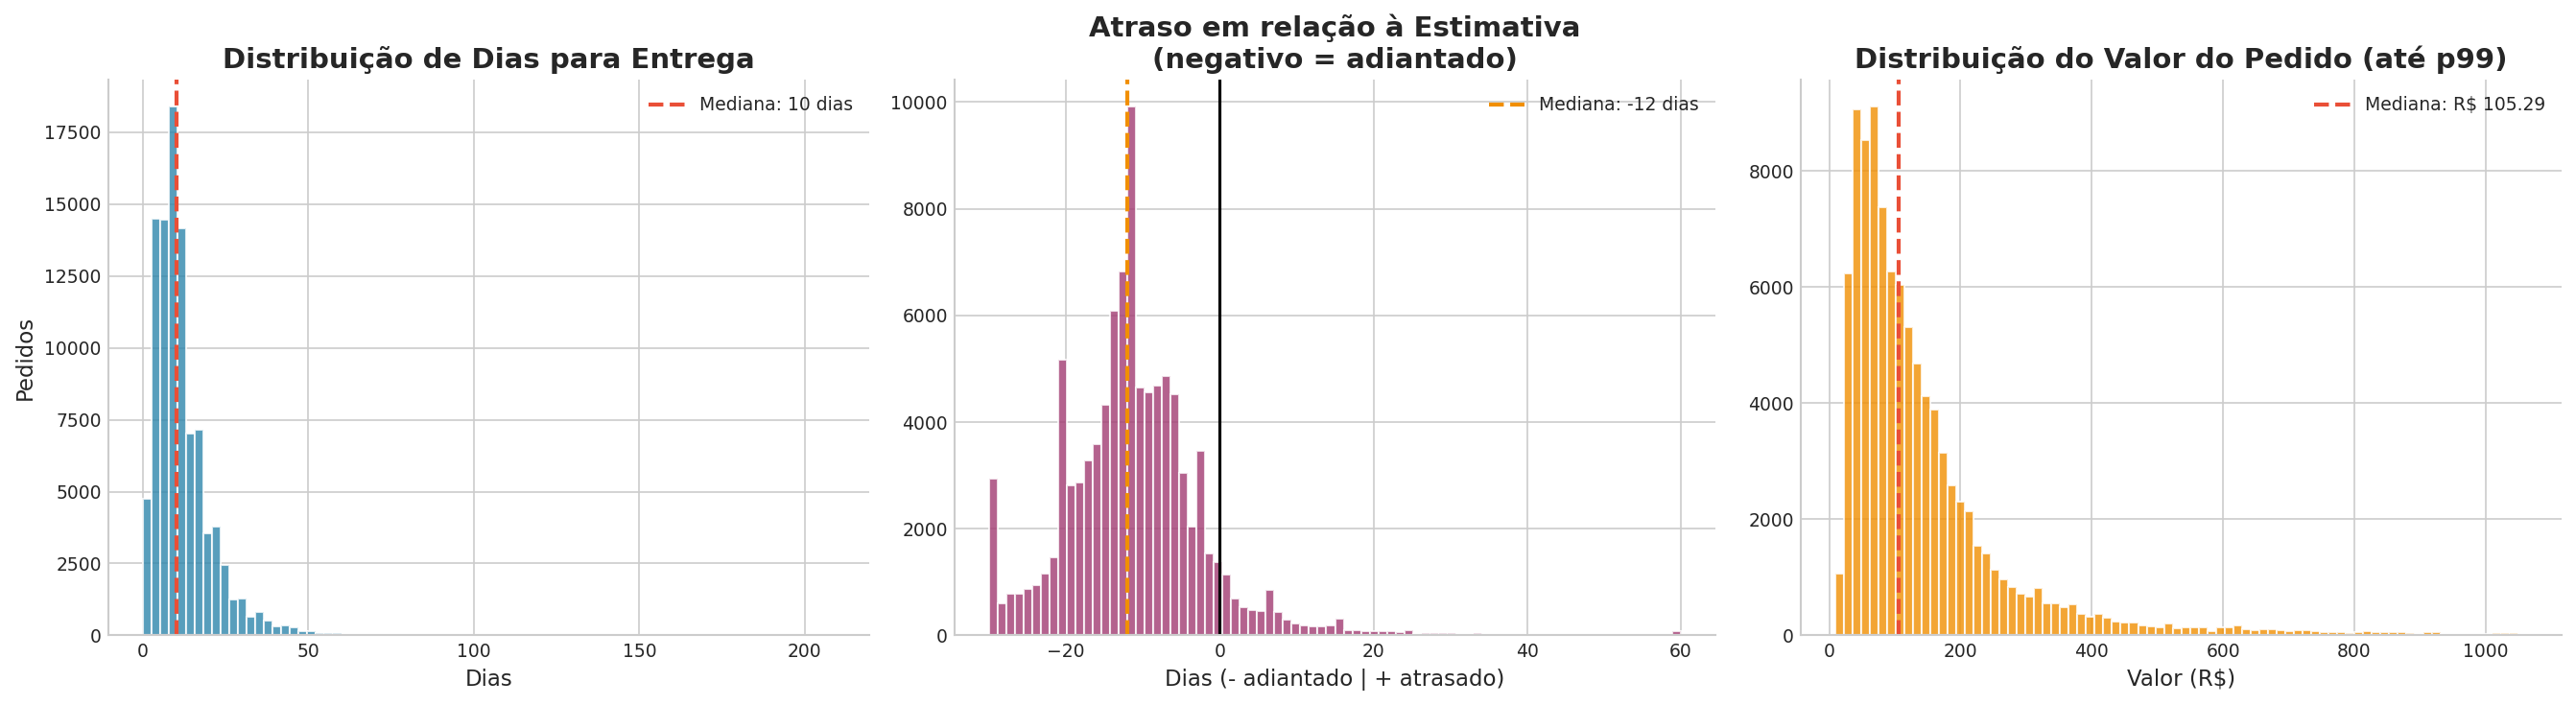

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Dias de entrega
d_data = delivered['delivery_days'].dropna()
axes[0].hist(d_data, bins=80, color='#2E86AB', alpha=0.8, edgecolor='white')
axes[0].axvline(d_data.median(), color='#E94F37', linestyle='--', linewidth=2, label=f'Mediana: {d_data.median():.0f} dias')
axes[0].set_title('Distribuição de Dias para Entrega', fontweight='bold')
axes[0].set_xlabel('Dias')
axes[0].set_ylabel('Pedidos')
axes[0].legend()

# Atraso relativo à estimativa
delay_data = delivered['delivery_delay_days'].dropna()
colors_delay = ['#E94F37' if x > 0 else '#44BBA4' for x in delay_data.clip(-30, 60)]
axes[1].hist(delay_data.clip(-30, 60), bins=80, color='#A23B72', alpha=0.8, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='-', linewidth=1.5)
axes[1].axvline(delay_data.median(), color='#F18F01', linestyle='--', linewidth=2, label=f'Mediana: {delay_data.median():.0f} dias')
axes[1].set_title('Atraso em relação à Estimativa\n(negativo = adiantado)', fontweight='bold')
axes[1].set_xlabel('Dias (- adiantado | + atrasado)')
axes[1].legend()

# Valor total do pedido
val_data = df['total_order_value'].dropna()
val_p99 = val_data.quantile(0.99)
axes[2].hist(val_data[val_data <= val_p99], bins=80, color='#F18F01', alpha=0.8, edgecolor='white')
axes[2].axvline(val_data.median(), color='#E94F37', linestyle='--', linewidth=2, label=f'Mediana: R$ {val_data.median():.2f}')
axes[2].set_title(f'Distribuição do Valor do Pedido (até p99)', fontweight='bold')
axes[2].set_xlabel('Valor (R$)')
axes[2].legend()

plt.tight_layout()
save_fig('02_distribuicoes_pos_etl')
plt.show()

## 5. Salvando o Dataset Processado

In [9]:
print('Salvando orders_enriched.parquet...')
save_processed(df, 'orders_enriched')
print('\n✓ Pronto! Dataset central salvo em data/processed/')

Salvando orders_enriched.parquet...


  ✓ Salvo: data/processed/orders_enriched.parquet (99,441 linhas)

✓ Pronto! Dataset central salvo em data/processed/


## 6. Dicionário de Dados — orders_enriched

| Coluna | Tipo | Descrição |
|--------|------|-----------|
| `order_id` | str | Identificador único do pedido |
| `customer_id` | str | ID do cliente neste pedido |
| `customer_unique_id` | str | ID único do cliente real |
| `order_status` | str | Status final do pedido |
| `order_purchase_timestamp` | datetime | Data/hora da compra |
| `order_delivered_customer_date` | datetime | Data de entrega real |
| `order_estimated_delivery_date` | datetime | Data estimada de entrega |
| `n_items` | int | Número de itens no pedido |
| `revenue` | float | Soma dos preços (sem frete) |
| `freight` | float | Total de frete |
| `total_order_value` | float | revenue + freight |
| `main_category` | str | Categoria do produto principal (EN) |
| `payment_type` | str | Método de pagamento predominante |
| `payment_installments` | int | Número de parcelas |
| `payment_value` | float | Valor total pago |
| `review_score` | float | Nota de avaliação (1–5) |
| `has_comment` | bool | Cliente deixou comentário? |
| `customer_state` | str | Estado do cliente |
| `delivery_days` | float | Dias para entrega (compra → entrega) |
| `days_to_estimated` | float | Prazo estimado em dias |
| `delivery_delay_days` | float | Atraso relativo (+ = atrasado) |
| `delivered_on_time` | bool | Entregue no prazo? |
| `purchase_year` | int | Ano da compra |
| `purchase_month` | int | Mês da compra |
| `purchase_day_of_week` | str | Dia da semana |
| `purchase_hour` | int | Hora do dia |

---
**Próximo:** `03_analise_receita.ipynb`